In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Saving the trained model
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/GeorgeMcIntire/fake_real_news_dataset/main/fake_and_real_news_dataset.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset downloaded successfully!
Dataset Shape: (4594, 4)

Columns:
['idd', 'title', 'text', 'label']


,idd,title,text,label
0,Fq+C96tcx+,‘A target on Roe v. Wade ’: Oklahoma bill maki...,UPDATE: Gov. Fallin vetoed the bill on Friday....,REAL
1,bHUqK!pgmv,Study: women had to drive 4 times farther afte...,Ever since Texas laws closed about half of the...,REAL
2,4Y4Ubf%aTi,"Trump, Clinton clash in dueling DC speeches","Donald Trump and Hillary Clinton, now at the s...",REAL
3,_CoY89SJ@K,Grand jury in Texas indicts activists behind P...,A Houston grand jury investigating criminal al...,REAL
4,+rJHoRQVLe,"As Reproductive Rights Hang In The Balance, De...",WASHINGTON -- Forty-three years after the Supr...,REAL


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nLabel Distribution:")
print(df["label"].value_counts())

print("\nDataset Information:")
df.info()

Dataset Shape: (4594, 4)

Column Names:
Index(['idd', 'title', 'text', 'label'], dtype='object')

Missing Values:
idd      0
title    1
text     0
label    0
dtype: int64

Duplicate Rows:
0

Label Distribution:
label
REAL    2297
FAKE    2297
Name: count, dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4594 entries, 0 to 4593
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   idd     4594 non-null   object
 1   title   4593 non-null   object
 2   text    4594 non-null   object
 3   label   4594 non-null   object
dtypes: object(4)
memory usage: 143.7+ KB


In [5]:
# Remove missing values
df = df.dropna(subset=["title", "text", "label"])

# Remove duplicate records
df = df.drop_duplicates(subset=["title", "text"])

# Clean labels
df["label"] = df["label"].str.upper().str.strip()

# Keep only REAL and FAKE news
df = df[df["label"].isin(["REAL", "FAKE"])]

# Combine title and article text
df["news"] = df["title"] + " " + df["text"]

print("Data Cleaning Completed!")

print("Final Dataset Shape:", df.shape)

print("\nLabel Distribution:")
print(df["label"].value_counts())

Data Cleaning Completed!
Final Dataset Shape: (4571, 5)

Label Distribution:
label
FAKE    2294
REAL    2277
Name: count, dtype: int64


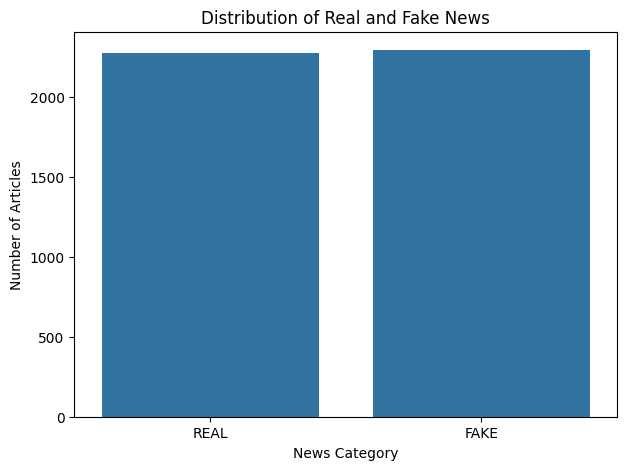

In [6]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Real and Fake News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.show()

In [7]:
def clean_text(text):

    text = str(text)

    # Convert text into lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_news"] = df["news"].apply(clean_text)

print("Text Preprocessing Completed!")

display(df[["news", "clean_news"]].head())

Text Preprocessing Completed!


,news,clean_news
0,‘A target on Roe v. Wade ’: Oklahoma bill maki...,a target on roe v wade oklahoma bill making it...
1,Study: women had to drive 4 times farther afte...,study women had to drive times farther after t...
2,"Trump, Clinton clash in dueling DC speeches Do...",trump clinton clash in dueling dc speeches don...
3,Grand jury in Texas indicts activists behind P...,grand jury in texas indicts activists behind p...
4,"As Reproductive Rights Hang In The Balance, De...",as reproductive rights hang in the balance deb...


In [8]:
# Input features
X = df["clean_news"]

# Target labels
y = df["label"].map({
    "REAL": 1,
    "FAKE": 0
})

print("Features and labels prepared successfully!")

print("\nFeatures shape:", X.shape)
print("Labels shape:", y.shape)

print("\nLabel distribution:")
print(y.value_counts())

Features and labels prepared successfully!

Features shape: (4571,)
Labels shape: (4571,)

Label distribution:
label
0    2294
1    2277
Name: count, dtype: int64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Dataset splitting completed!
Training data: 3656
Testing data: 915


In [10]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_df=0.7,
    min_df=2,
    ngram_range=(1, 2),
    max_features=50000
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization Completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF Vectorization Completed!
Training matrix shape: (3656, 50000)
Testing matrix shape: (915, 50000)


In [11]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [12]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [13]:
models = {
    "Logistic Regression": lr_predictions,
    "Naive Bayes": nb_predictions
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.919126,0.952607,0.881579,0.915718
1,Naive Bayes,0.886339,0.843750,0.947368,0.892562


<Figure size 1000x600 with 0 Axes>

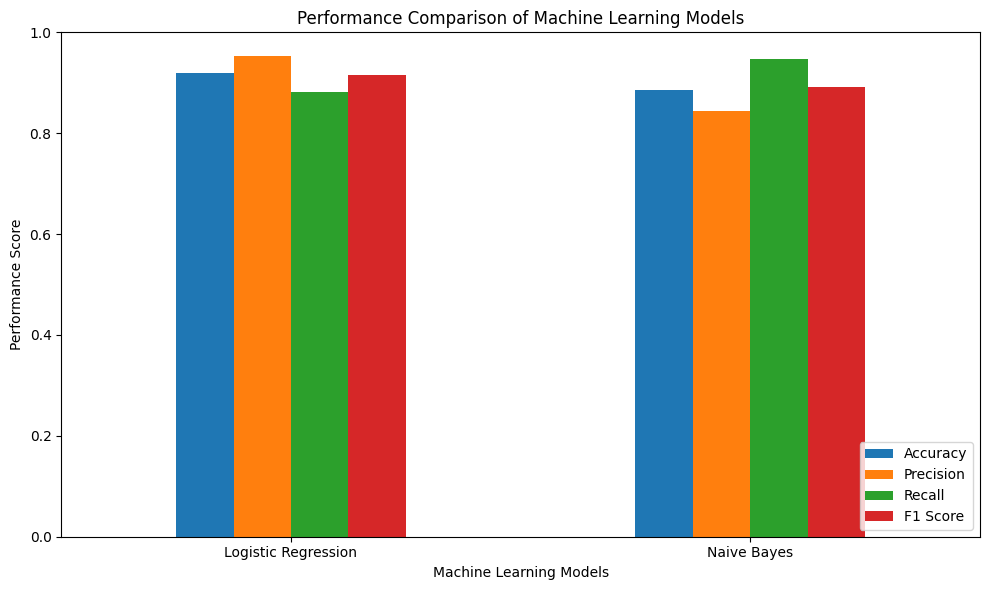

In [14]:
plt.figure(figsize=(10, 6))

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Machine Learning Models")

plt.xlabel("Machine Learning Models")

plt.ylabel("Performance Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

In [15]:
best_model_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

if best_model_name == "Logistic Regression":

    best_model = lr_model
    best_predictions = lr_predictions

else:

    best_model = nb_model
    best_predictions = nb_predictions

print("Best Performing Model:", best_model_name)

Best Performing Model: Logistic Regression


In [18]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1],
        target_names=["FAKE", "REAL"],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.89      0.96      0.92       459
        REAL       0.95      0.88      0.92       456

    accuracy                           0.92       915
   macro avg       0.92      0.92      0.92       915
weighted avg       0.92      0.92      0.92       915



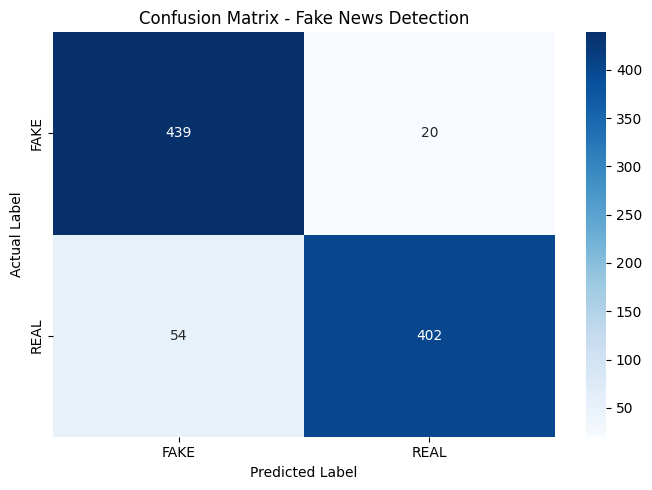

In [19]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["FAKE", "REAL"],
    yticklabels=["FAKE", "REAL"]
)

plt.title("Confusion Matrix - Fake News Detection")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.tight_layout()

plt.show()

In [20]:
joblib.dump(
    best_model,
    "fake_news_model.pkl"
)

joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

print("Model saved successfully!")

print("TF-IDF Vectorizer saved successfully!")

Model saved successfully!
TF-IDF Vectorizer saved successfully!


In [22]:
def predict_news(news):

    cleaned_news = clean_text(news)

    transformed_news = tfidf.transform([cleaned_news])

    prediction = best_model.predict(
        transformed_news
    )[0]

    probabilities = best_model.predict_proba(
        transformed_news
    )[0]

    confidence = max(probabilities) * 100

    if prediction == 1:

        result = "LIKELY REAL NEWS"

    else:

        result = "LIKELY FAKE NEWS"

    print("\nPrediction:", result)

    print("Model Confidence:", round(confidence, 2), "%")

    return result

In [28]:
news = "Scientists discover a new planet outside our solar system"

cleaned_news = clean_text(news)
transformed_news = tfidf.transform([cleaned_news])

prediction = best_model.predict(transformed_news)[0]

if prediction == 1:
    print("Prediction: LIKELY REAL NEWS")
else:
    print("Prediction: LIKELY FAKE NEWS")

Prediction: LIKELY FAKE NEWS


In [29]:
from google.colab import files

files.download("fake_news_model.pkl")

files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
results_df.to_csv(
    "model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

files.download("model_evaluation_results.csv")

Evaluation results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
df.to_csv(
    "cleaned_news_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

files.download("cleaned_news_dataset.csv")

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>